# Movimiento browniano de microesferas

In [13]:
pip install SciencePlots

Note: you may need to restart the kernel to use updated packages.


## 1. Configuración

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import trackpy as tp
import scienceplots                     
import warnings

tp.quiet()
warnings.filterwarnings('ignore', category=UserWarning, module='trackpy')
plt.style.use(['science', 'no-latex'])
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110,
                     'axes.grid': True, 'grid.alpha': 0.3})

VIDEO = "video1.avi"
FRAME_0 = 0                 # primer frame
N_FRAMES = None             # None = hasta el final
FRAME_CATALOGO = 0          # frame donde se arma el catálogo de detecciones

T_K = 298.15                # K
RADIO_UM = 1.62             # radio nominal de las esferas
RADIO_UM_ERR = 0.08         # dispersión del lote 
ESCALA_UM_PX = 0.0946       # calibración
ESCALA_UM_PX_ERR = 0.002
K_B = 1.380649e-23
ETA_REF = 0.890             # viscosidad del solvente puro, cota inferior [mPa s]

CANAL = 'verde'             # 'verde' | 'rojo' | 'azul' | 'gris'
ROI = None                  # (y0, y1, x0, x1); None = automático
RESTAR_FONDO = True
N_FONDO = 60                # frames para la mediana del fondo

DIAMETRO = 35               
INVERTIR = True             # partículas oscuras sobre fondo claro
MINMASS = None              # umbral absoluto; None = usar PERCENTIL_MASA
PERCENTIL_MASA = 92
MAXSIZE = None

SEARCH_RANGE = 8            # px entre frames consecutivos
MEMORIA = 3
MIN_LARGO = 100             # frames

SELECCION = 'masa'          # 'masa' | 'duracion' (valores de SELECCION; dos formas de análisis)
POSICION_INICIAL = None    
ID_PART_MANUAL = 344

FRACCION_MSD = 0.25         # fracción de la trayectoria usada como retardo temporal
MIN_PARTICULAS_LAG = 999      # mínimo de trayectorias para promediar un retardo temporal

N_PERFIL = 8                # frames por trayectoria para el tamaño aparente

MAX_HUECOS = 0.10           # criterios de aceptación, fijados a priori
MAX_SIGMA_PX = 1.5
MIN_RAZON = 0.25
MAX_RAZON = 3.0

SALIDA = "figuras"
FORMATO = 'svg'
DPI = 300
os.makedirs(SALIDA, exist_ok=True)

try:
    import numba                                              # noqa: F40
    ENGINE = 'numba'
except ImportError:
    ENGINE = 'auto'


def guardar(nombre):
    ruta = os.path.join(SALIDA, f"{nombre}.{FORMATO}")
    plt.savefig(ruta, dpi=DPI, bbox_inches='tight')
    return ruta


def eta_de_D(D, R_um=RADIO_UM):
    """Viscosidad [mPa s] desde D [um^2/s] por Stokes-Einstein."""
    return K_B * T_K / (6 * np.pi * R_um * 1e-6 * D * 1e-12) * 1e3

## 2. Video

In [15]:
cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened():
    raise IOError(f"No se pudo abrir {VIDEO}")
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ANCHO = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
ALTO = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
DT = 1.0 / FPS

print(f"{VIDEO}: {ANCHO}x{ALTO} px, {N_TOTAL} frames, {FPS:.3f} fps, "
      f"{N_TOTAL/FPS:.1f} s")


def extraer_canal(frame, canal=CANAL):
    if frame.ndim == 2:
        return frame.astype(np.uint8)
    i = {'azul': 0, 'verde': 1, 'rojo': 2}.get(canal)
    return frame[:, :, i] if i is not None else cv2.cvtColor(frame,
                                                             cv2.COLOR_BGR2GRAY)


def leer_frames(video, f0, n, roi=None, fondo=None):
    """Generador de frames en punto flotante, sin recortar a [0, 255]."""
    cap = cv2.VideoCapture(video)
    cap.set(cv2.CAP_PROP_POS_FRAMES, f0)
    k = 0
    while n is None or k < n:
        ok, frame = cap.read()
        if not ok:
            break
        g = extraer_canal(frame).astype(np.float32)
        if roi is not None:
            g = g[roi[0]:roi[1], roi[2]:roi[3]]
        if fondo is not None:
            g = 128.0 + g - fondo
        yield f0 + k, g
        k += 1
    cap.release()


def un_frame(k, roi=None, fondo=None):
    return next(leer_frames(VIDEO, int(k), 1, roi, fondo))[1]


def figura(img, nombre, cmap='gray', vmin=None, vmax=None, label=''):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xlabel('$x$ [px]')
    ax.set_ylabel('$y$ [px]')
    ax.grid(False)
    plt.colorbar(im, ax=ax, label=label, fraction=0.046)
    plt.tight_layout()
    guardar(nombre)
    plt.show()

video1.avi: 1280x1024 px, 844 frames, 12.501 fps, 67.5 s


## 3. Procesamiento de imagen


A. canal
   azul   media  62.2   S/R  0.76
   verde  media 122.3   S/R  1.68
   rojo   media  82.0   S/R  1.35
   elegido: verde


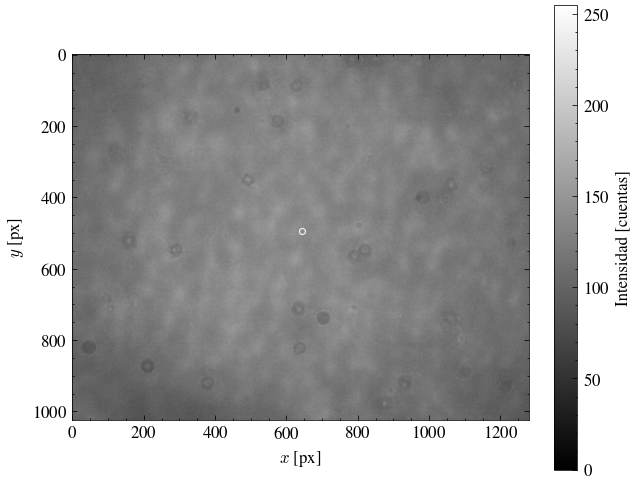


B. ROI (5, 1018, 5, 1274) -> 1013x1269 px


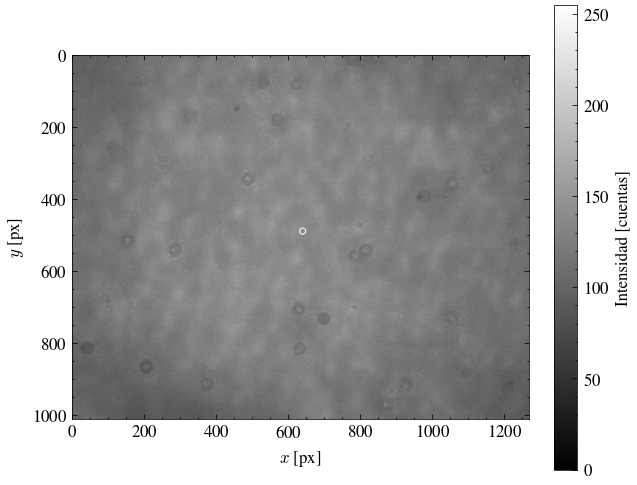


C. fondo: mediana de 60 frames


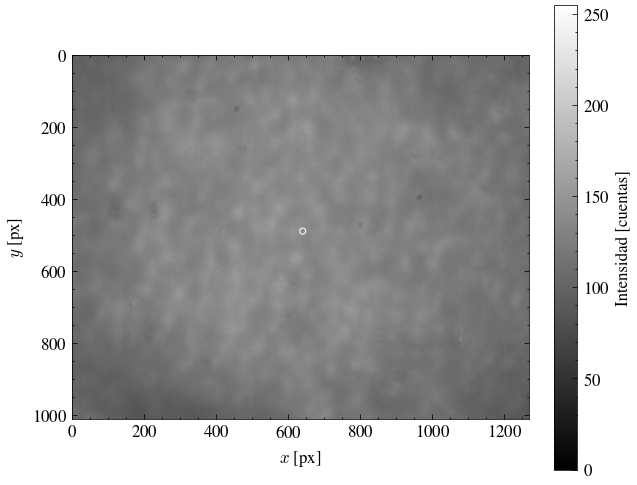

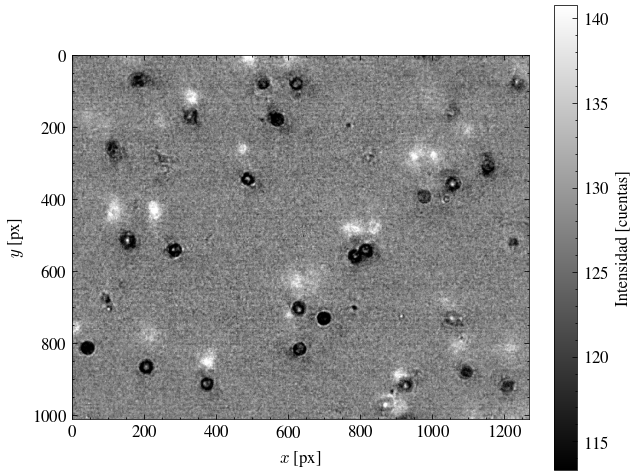


D. pasa-banda


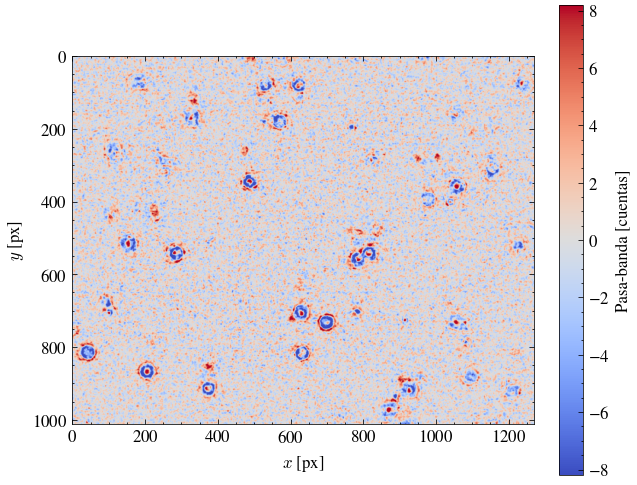


E. detección


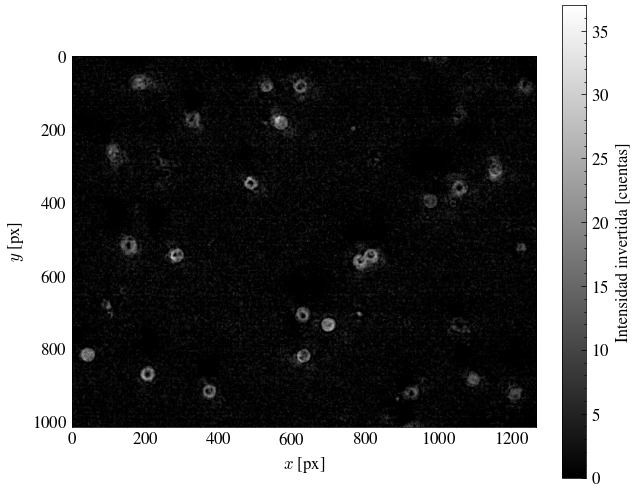

   masa(99%)/masa(50%) = 11.18
   umbral 1925: 289 -> 24 detecciones


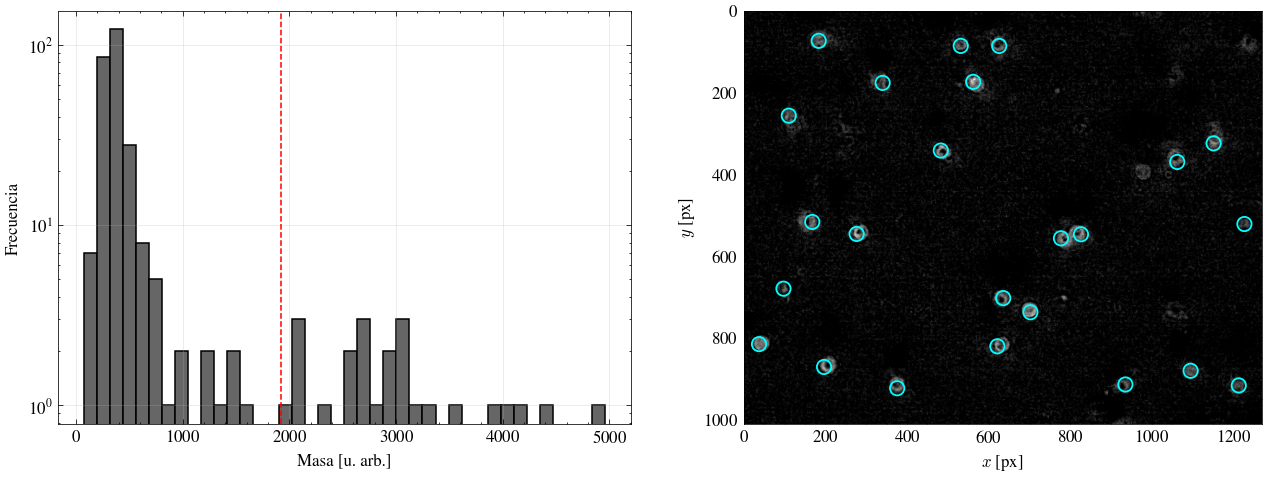

In [16]:
cap = cv2.VideoCapture(VIDEO)
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_CATALOGO)
ok, frame_crudo = cap.read()
cap.release()
if not ok:
    raise IOError(f"No se pudo leer el frame {FRAME_CATALOGO}")

# A. Canal. Se compara la amplitud de la estructura a la escala de la partícula
#    contra la dispersión a escala de un píxel.
print("\nA. canal")
for nombre, c in [('azul', 0), ('verde', 1), ('rojo', 2)]:
    ch = frame_crudo[:, :, c].astype(float)
    senal = (cv2.GaussianBlur(ch, (0, 0), 3) -
             cv2.GaussianBlur(ch, (0, 0), max(DIAMETRO / 2, 1))).std()
    ruido = (ch - cv2.GaussianBlur(ch, (0, 0), 1)).std()
    print(f"   {nombre:6s} media {ch.mean():5.1f}   S/R {senal/ruido:5.2f}")
print(f"   elegido: {CANAL}")

img_canal = extraer_canal(frame_crudo)
figura(img_canal, 'A_canal', vmin=0, vmax=255, label='Intensidad [cuentas]')

# B. Región de interés. Los filtros posteriores son convoluciones y un borde
#    abrupto del encuadre genera una respuesta comparable a la de una partícula.
if ROI is None:
    fy = np.where(img_canal.mean(axis=1) > 30)[0]
    fx = np.where(img_canal.mean(axis=0) > 30)[0]
    ROI = (int(fy.min()) + 5, int(fy.max()) - 5,
           int(fx.min()) + 5, int(fx.max()) - 5)
print(f"\nB. ROI {ROI} -> {ROI[1]-ROI[0]}x{ROI[3]-ROI[2]} px")
img_roi = img_canal[ROI[0]:ROI[1], ROI[2]:ROI[3]]
figura(img_roi, 'B_roi', vmin=0, vmax=255, label='Intensidad [cuentas]')

# C. Fondo. Mediana y no promedio: el promedio arrastra el oscurecimiento
#    transitorio de cada partícula y deja un rastro.
if RESTAR_FONDO:
    idx = np.linspace(FRAME_0, FRAME_0 + (N_FRAMES or N_TOTAL - FRAME_0) - 1,
                      N_FONDO).astype(int)
    pila = []
    cap = cv2.VideoCapture(VIDEO)
    for k in idx:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(k))
        ok, fr = cap.read()
        if ok:
            pila.append(extraer_canal(fr)[ROI[0]:ROI[1],
                                          ROI[2]:ROI[3]].astype(np.float32))
    cap.release()
    FONDO = np.median(np.dstack(pila), axis=2)
    print(f"\nC. fondo: mediana de {len(pila)} frames")
else:
    FONDO = None

img_limpio = un_frame(FRAME_CATALOGO, ROI, FONDO)
if RESTAR_FONDO:
    figura(FONDO, 'C1_fondo', vmin=0, vmax=255, label='Intensidad [cuentas]')
    figura(img_limpio, 'C2_sin_fondo', label='Intensidad [cuentas]',
           vmin=img_limpio.mean() - 4*img_limpio.std(),
           vmax=img_limpio.mean() + 4*img_limpio.std())


def pasabanda(g, diametro):
    """Gaussiana de 1 px menos caja de lado diámetro. Conserva el signo."""
    g = np.asarray(g, dtype=np.float32)
    return (cv2.GaussianBlur(g, (0, 0), 1) -
            cv2.blur(g, (int(diametro), int(diametro))))


# D. Pasa-banda. Elimina la iluminación residual (escala > diámetro) y el ruido
#    de píxel (escala < 1 px).
print(f"\nD. pasa-banda")
img_banda = pasabanda(img_limpio, DIAMETRO)
v_ = np.percentile(np.abs(img_banda), 99.5)
figura(img_banda, 'D_pasabanda', cmap='coolwarm', vmin=-v_, vmax=v_,
       label='Pasa-banda [cuentas]')


def preparar(g):
    """Imagen sobre la que corre el detector."""
    s = -1.0 if INVERTIR else 1.0
    return np.clip(s * (np.asarray(g, dtype=float) - np.median(g)), 0, None)


def detectar(g, minmass=None):
    img = preparar(g)
    f = tp.locate(img, DIAMETRO, minmass=minmass, invert=False,
                  preprocess=True, engine=ENGINE)
    if MAXSIZE is not None and len(f):
        f = f[f['size'] <= MAXSIZE]
    return f.reset_index(drop=True)


# E. Imagen de detección y umbral de masa. El umbral se fija por percentil
#    porque la escala de masa depende de DIAMETRO. El cociente
#    masa(99%)/masa(50%) verifica que haya dos poblaciones separadas.
print("\nE. detección")
img_det = preparar(img_limpio)
figura(img_det, 'E_detección', cmap='gray',
       label='Intensidad invertida [cuentas]')

f_todo = detectar(img_limpio)
if len(f_todo) == 0:
    raise ValueError("Sin detecciones: revisar DIAMETRO.")
contraste = np.percentile(f_todo['mass'], 99) / np.percentile(f_todo['mass'], 50)
print(f"   masa(99%)/masa(50%) = {contraste:.2f}")
if contraste < 1.5:
    print("Sin poblaciones separadas: el percentil puede cortar partículas")

if MINMASS is not None:
    UMBRAL = float(MINMASS)
elif PERCENTIL_MASA is None:
    UMBRAL = None
else:
    UMBRAL = float(np.percentile(f_todo['mass'], PERCENTIL_MASA))

f_sel = detectar(img_limpio, minmass=UMBRAL)
if len(f_sel) == 0:
    raise ValueError("El umbral no dejó detecciones: bajar PERCENTIL_MASA.")
print(f"   umbral {UMBRAL:.0f}: {len(f_todo)} -> {len(f_sel)} detecciones")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(f_todo['mass'], bins=40, color='0.4', edgecolor='k')
if UMBRAL is not None:
    ax[0].axvline(UMBRAL, color='r', ls='--')
ax[0].set_yscale('log')
ax[0].set_xlabel('Masa [u. arb.]')
ax[0].set_ylabel('Frecuencia')
ax[1].imshow(img_det, cmap='gray')
for _, fi in f_sel.iterrows():
    ax[1].add_patch(plt.Circle((fi['x'], fi['y']), DIAMETRO/2, fill=False,
                               ec='cyan', lw=1.2))
ax[1].set_xlabel('$x$ [px]')
ax[1].set_ylabel('$y$ [px]')
ax[1].grid(False)
plt.tight_layout()
guardar('E_umbral')
plt.show()

## 4. Catálogo de detecciones

El índice es una etiqueta de esta tabla, no el identificador de trayectoria.  
Las coordenadas están referidas a la imagen ya recortada por el ROI.

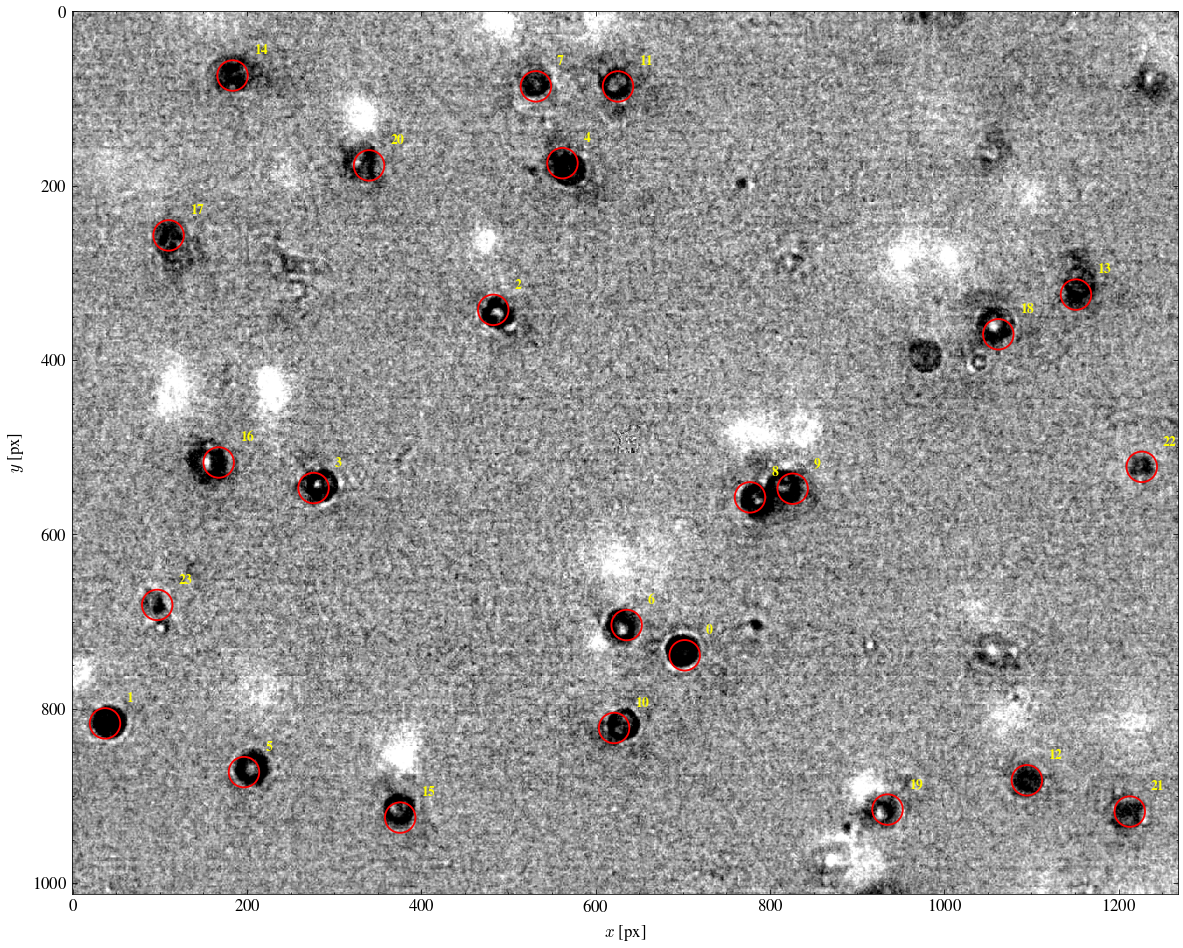

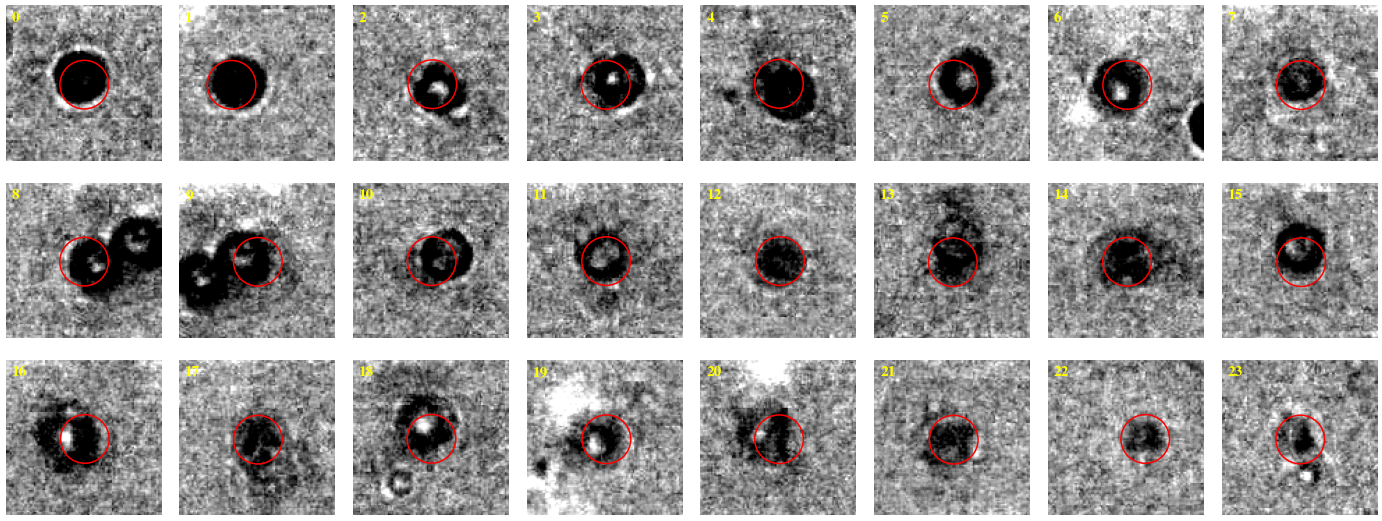

         x      y    mass  size
0    702.2  738.6  4956.9  11.6
1     37.2  816.7  4357.2  11.5
2    482.6  342.3  4211.6  11.2
3    276.4  546.7  3980.7  10.2
4    562.0  174.0  3965.4   9.6
5    196.6  872.6  3524.1   9.9
6    635.6  703.9  3253.4  11.3
7    531.5   85.9  3194.6  11.1
8    777.1  557.4  3111.2  10.3
9    826.1  547.5  3068.8  10.2
10   621.2  822.0  3032.3  10.3
11   625.7   86.0  2976.2  13.0
12  1094.8  882.0  2976.1  11.1
13  1151.1  324.8  2780.0  10.0
14   183.5   73.5  2714.3  11.4
15   375.8  924.8  2696.8  10.3
16   167.6  517.4  2642.3   9.8
17   110.1  256.9  2595.9  10.9
18  1062.0  370.3  2519.3  10.1
19   934.9  915.6  2270.9   9.7
20   340.1  176.6  2145.6  11.1
21  1212.8  917.9  2143.8  10.7
22  1226.6  522.4  2090.7   9.1
23    97.1  680.8  1938.7   8.3


In [17]:
catalogo = f_sel[['x', 'y', 'mass', 'size']].sort_values(
    'mass', ascending=False).reset_index(drop=True).round(1)
vmin_, vmax_ = np.percentile(img_limpio, [1, 99])

fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(img_limpio, cmap='gray', vmin=vmin_, vmax=vmax_)
for i, fl in catalogo.iterrows():
    ax.add_patch(plt.Circle((fl['x'], fl['y']), DIAMETRO/2, fill=False,
                            ec='r', lw=1.2))
    ax.text(fl['x'] + DIAMETRO*0.7, fl['y'] - DIAMETRO*0.7, str(i),
            color='yellow', fontsize=9, weight='bold')
ax.set_xlabel('$x$ [px]')
ax.set_ylabel('$y$ [px]')
ax.grid(False)
plt.tight_layout()
guardar('catalogo')
plt.show()

W = max(int(1.6*DIAMETRO), 30)
ncol = 8
nfil = int(np.ceil(len(catalogo)/ncol))
alto_, ancho_ = img_limpio.shape
fig, ax = plt.subplots(nfil, ncol, figsize=(1.6*ncol, 1.7*nfil))
ax = np.atleast_1d(ax).ravel()
for a in ax:
    a.axis('off')
for i, fl in catalogo.iterrows():
    xi = int(np.clip(fl['x'], W, ancho_ - W))
    yi = int(np.clip(fl['y'], W, alto_ - W))
    ax[i].imshow(img_limpio[yi-W:yi+W, xi-W:xi+W], cmap='gray',
                 vmin=vmin_, vmax=vmax_)
    ax[i].add_patch(plt.Circle((fl['x']-xi+W, fl['y']-yi+W), DIAMETRO/2,
                               fill=False, ec='r', lw=1.0))
    ax[i].text(0.04, 0.96, str(i), color='yellow', fontsize=10, weight='bold',
               ha='left', va='top', transform=ax[i].transAxes)
plt.tight_layout()
guardar('catalogo_recortes')
plt.show()
print(catalogo.to_string())

In [6]:
POSICION_INICIAL = (482.6,342.3)

## 5. Detección y seguimiento

SEARCH_RANGE debe superar el paso browniano típico y quedar por debajo de la  
separación entre partículas. Un valor mayor que el necesario no alarga las  
trayectorias útiles: incorpora detecciones espurias y degrada sigma.

In [18]:
paso = np.sqrt(4*0.05*DT)/ESCALA_UM_PX
print(f"paso esperado {paso:.2f} px/frame, SEARCH_RANGE {SEARCH_RANGE} px "
      f"({SEARCH_RANGE/paso:.1f}x)")

lotes = []
for k, fr in leer_frames(VIDEO, FRAME_0, N_FRAMES, ROI, FONDO):
    fk = detectar(fr, minmass=UMBRAL)
    fk['frame'] = k
    lotes.append(fk)
    if (k - FRAME_0) % 100 == 0:
        print(f"   frame {k}: {len(fk)}")

detecciones = pd.concat(lotes, ignore_index=True)
trayectorias = tp.link(detecciones, search_range=SEARCH_RANGE, memory=MEMORIA)
trayectorias = tp.filter_stubs(trayectorias, MIN_LARGO).reset_index(drop=True)
if len(trayectorias) == 0:
    raise ValueError(f"Ninguna trayectoria alcanza {MIN_LARGO} frames.")

resumen = trayectorias.groupby('particle').agg(
    N=('frame', 'size'), masa=('mass', 'median'), tam=('size', 'median'),
    x0=('x', 'first'), y0=('y', 'first')).sort_values('masa', ascending=False)
print(f"\n{len(detecciones)/len(lotes):.1f} detecciones por frame, "
      f"{len(resumen)} trayectorias >= {MIN_LARGO} frames")
print(resumen.head(10).round(1).to_string())


def trayectoria_um(pid, tabla=None):
    """(tabla reindexada, x[um], y[um], fraccion de frames interpolados)."""
    tabla = trayectorias if tabla is None else tabla
    g = tabla[tabla['particle'] == pid].sort_values('frame')
    k0, k1 = int(g['frame'].min()), int(g['frame'].max())
    gi = g.set_index('frame').reindex(range(k0, k1 + 1))
    hue = float(gi['x'].isna().mean())
    gi[['x', 'y']] = gi[['x', 'y']].interpolate()
    return (gi, gi['x'].to_numpy()*ESCALA_UM_PX,
            gi['y'].to_numpy()*ESCALA_UM_PX, hue)

paso esperado 1.34 px/frame, SEARCH_RANGE 8 px (6.0x)
   frame 0: 24
   frame 100: 18
   frame 200: 17
   frame 300: 14
   frame 400: 9
   frame 500: 13
   frame 600: 14
   frame 700: 13
   frame 800: 11

14.1 detecciones por frame, 26 trayectorias >= 100 frames
            N    masa   tam     x0     y0
particle                                 
10        267  6061.6  11.6  276.4  546.7
20        324  4411.7  11.6  482.6  342.3
7         163  4350.6  11.1  702.2  738.6
823       118  3612.4  11.3  472.8  275.5
77        345  3599.1  10.7  552.2  144.4
82        107  3474.4  11.0   33.3  784.5
101       177  3390.4  10.0  826.2  521.6
788       114  3355.4  10.8  607.9  708.0
658       172  3349.5   9.9  232.5  434.8
344       177  3338.0  10.8  595.7  750.5


## 6. Deriva 

deriva neta: (+0.11, -6.77) um en 67.4 s   |v| medio = 0.101 um/s


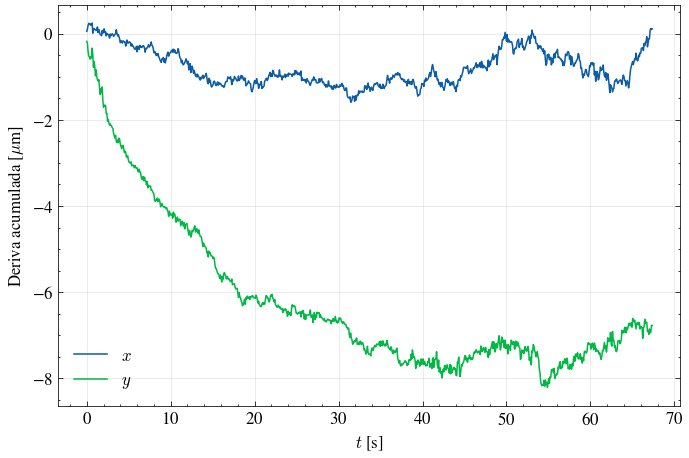

In [19]:
deriva = tp.compute_drift(trayectorias)
t_der = (deriva.index.to_numpy() - deriva.index.min())*DT
dx_um = deriva['x'].to_numpy()*ESCALA_UM_PX
dy_um = deriva['y'].to_numpy()*ESCALA_UM_PX
print(f"deriva neta: ({dx_um[-1]:+.2f}, {dy_um[-1]:+.2f}) um en {t_der[-1]:.1f} s"
      f"   |v| medio = {np.hypot(dx_um[-1], dy_um[-1])/t_der[-1]:.3f} um/s")

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.plot(t_der, dx_um, label='$x$')
ax.plot(t_der, dy_um, label='$y$')
ax.set_xlabel('$t$ [s]')
ax.set_ylabel(r'Deriva acumulada [$\mu$m]')
ax.legend()
plt.tight_layout()
guardar('deriva')
plt.show()

## 7. Selección de una partícula

El criterio por defecto es la masa y no la duración: las esferas derivan y  
salen del campo mientras las detecciones débiles persisten, de modo que la  
trayectoria más larga tiende a no ser una esfera.

id 344: frames 279-456, 14.2 s, 0.6 % interpolado


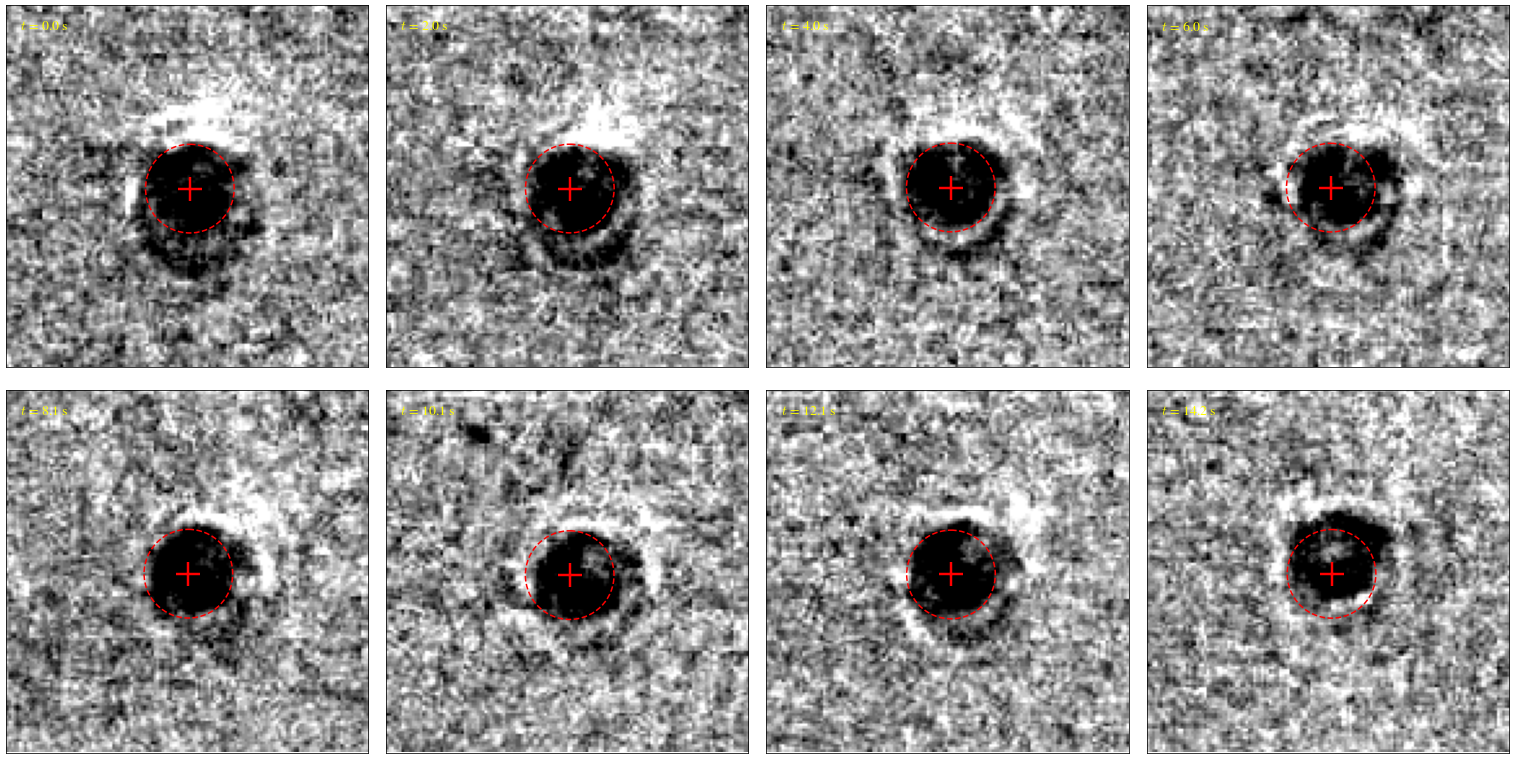

In [20]:
if ID_PART_MANUAL is not None:
    ID_PART = ID_PART_MANUAL
    if ID_PART not in resumen.index:
        raise ValueError(f"Ids válidos: {list(resumen.index[:10])}")
elif POSICION_INICIAL is not None:
    x0, y0 = POSICION_INICIAL
    disp = np.sort(trayectorias['frame'].unique())
    k_ref = int(disp[np.argmin(np.abs(disp - FRAME_CATALOGO))])
    cerca = trayectorias[trayectorias['frame'] == k_ref]
    d = np.hypot(cerca['x'] - x0, cerca['y'] - y0)
    ID_PART = int(cerca.loc[d.idxmin(), 'particle'])
    print(f"selección por posición: id {ID_PART}, a {d.min():.1f} px")
elif SELECCION == 'duracion':
    ID_PART = int(resumen.sort_values('N', ascending=False).index[0])
else:
    ID_PART = int(resumen.index[0])

p, x_um, y_um, frac_huecos = trayectoria_um(ID_PART)
t_s = np.arange(len(p))*DT
K_INI, K_FIN = int(p.index[0]), int(p.index[-1])
print(f"id {ID_PART}: frames {K_INI}-{K_FIN}, {len(p)*DT:.1f} s, "
      f"{100*frac_huecos:.1f} % interpolado")

# Verificación: el círculo punteado marca el radio nominal de la esfera.
W = max(2*DIAMETRO, 40)
pc = trayectorias[trayectorias['particle'] == ID_PART].set_index('frame')
ref = un_frame(K_INI, ROI, FONDO)
vmin_, vmax_ = np.percentile(ref, [1, 99])
alto_, ancho_ = ref.shape

fig, ax = plt.subplots(2, 4, figsize=(14, 7.4))
for a, k in zip(ax.ravel(), np.linspace(K_INI, K_FIN, 8).astype(int)):
    if k not in pc.index:
        k = int(pc.index[np.argmin(np.abs(pc.index - k))])
    fr = un_frame(k, ROI, FONDO)
    xi = int(np.clip(pc.loc[k, 'x'], W, ancho_ - W))
    yi = int(np.clip(pc.loc[k, 'y'], W, alto_ - W))
    a.imshow(fr[yi-W:yi+W, xi-W:xi+W], cmap='gray', vmin=vmin_, vmax=vmax_)
    a.plot(pc.loc[k, 'x']-xi+W, pc.loc[k, 'y']-yi+W, '+', color='red',
           ms=16, mew=1.6)
    a.add_patch(plt.Circle((pc.loc[k, 'x']-xi+W, pc.loc[k, 'y']-yi+W),
                           RADIO_UM/ESCALA_UM_PX, fill=False, ec='red',
                           lw=1.0, ls='--'))
    a.text(0.04, 0.96, f'$t$ = {(k-K_INI)*DT:.1f} s', color='yellow',
           fontsize=9, ha='left', va='top', transform=a.transAxes)
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
guardar('verificacion')
plt.show()

## 8. Trayectoria

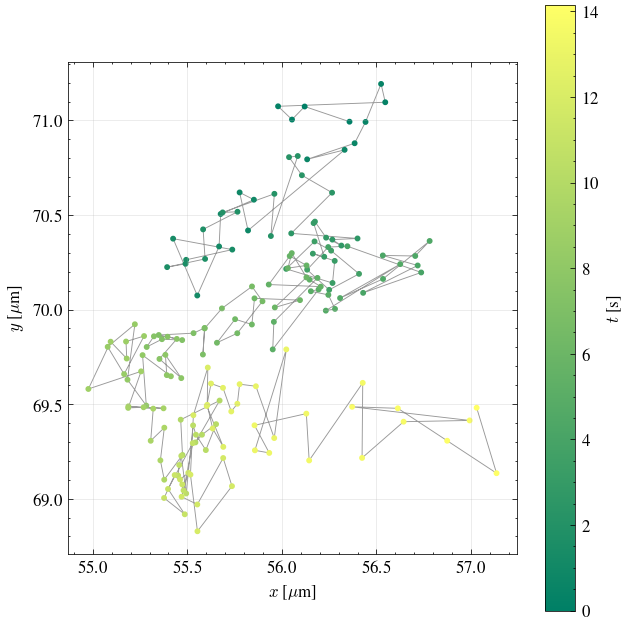

In [21]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(x_um, y_um, '-', lw=0.6, color='0.6', zorder=0)
sc = ax.scatter(x_um, y_um, c=t_s, cmap='summer', s=8)
plt.colorbar(sc, ax=ax, label='$t$ [s]')
ax.set_xlabel(r'$x$ [$\mu$m]')
ax.set_ylabel(r'$y$ [$\mu$m]')
ax.set_aspect('equal')
plt.tight_layout()
guardar('trayectoria')
plt.show()

## 9. MSD y ajuste

sigma 1.22 px
D     0.0489 +- 0.0035 um^2/s  ->  eta 2.76 mPa s
v     0.0421 +- 0.0444 um/s


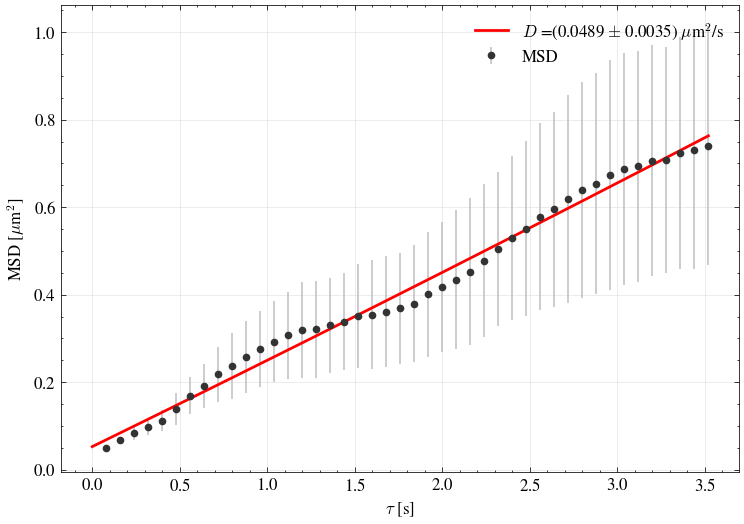

In [22]:
def msd(x, y, n_lags):
    """MSD sobre todos los pares. El error usa N/n pares independientes."""
    N = len(x)
    n_lags = min(n_lags, N - 1)
    lags = np.arange(1, n_lags + 1)
    val = np.empty(n_lags)
    err = np.empty(n_lags)
    for i, n in enumerate(lags):
        d2 = (x[n:] - x[:-n])**2 + (y[n:] - y[:-n])**2
        val[i] = d2.mean()
        err[i] = d2.std(ddof=1) / np.sqrt(max(N / n, 1))
    return lags, val, err


def ajustar(tau, msd_val, con_deriva=True):
    cols = [np.ones_like(tau), tau] + ([tau**2] if con_deriva else [])
    A = np.vstack(cols).T
    if len(tau) < A.shape[1] + 1:
        raise ValueError(f"{len(tau)} retardos para {A.shape[1]} parámetros.")
    coef, *_ = np.linalg.lstsq(A, msd_val, rcond=None)
    res = msd_val - A @ coef
    cov = (res @ res / (len(tau) - A.shape[1])) * np.linalg.pinv(A.T @ A)
    sigma = np.sqrt(max(coef[0], 0)) / 2
    D = coef[1] / 4
    dD = np.sqrt(cov[1, 1]) / 4
    v = np.sqrt(max(coef[2], 0)) if con_deriva else 0.0
    dv = np.sqrt(cov[2, 2]) / (2*v) if con_deriva and v > 0 else np.nan
    return sigma, D, dD, v, dv, coef, cov


lags, msd_val, msd_err = msd(x_um, y_um, int(FRACCION_MSD*len(x_um)))
tau = lags*DT
sg, D1, dD1, v1, dv1, _, _ = ajustar(tau, msd_val)

print(f"sigma {sg/ESCALA_UM_PX:.2f} px")
print(f"D     {D1:.4f} +- {dD1:.4f} um^2/s  ->  eta {eta_de_D(D1):.2f} mPa s")
print(f"v     {v1:.4f} +- {dv1:.4f} um/s")

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(tau, msd_val, yerr=msd_err, fmt='o', ms=4, color='0.2',
            ecolor='0.75', capsize=0, label='MSD')
tt = np.linspace(0, tau[-1], 300)
ax.plot(tt, 4*sg**2 + 4*D1*tt + (v1*tt)**2, 'r-', lw=1.8,
        label=( f"$D$ =({D1:.4f} $\\pm$ {dD1:.4f}) $\\mu$m$^2$/s"))
ax.set_xlabel(r'$\tau$ [s]')
ax.set_ylabel(r'MSD [$\mu$m$^2$]')
ax.legend()
plt.tight_layout()
guardar('msd_particula')
plt.show()

## 10. Conjunto de partículas

 id   N  huecos      masa  sigma_px      D     dD      v     eta  razon  acepta
 10 274  0.0255 6061.6123    0.0000 0.1217 0.0055 0.3638  1.1077 2.9853    True
 20 348  0.0690 4411.7250    2.1645 0.0192 0.0036 0.2577  7.0171 5.0219   False
  7 169  0.0355 4350.6396    0.8804 0.0779 0.0019 0.2548  1.7313 2.3739    True
823 121  0.0248 3612.4157    1.8582 0.0043 0.0072 0.3184 31.1385 5.3328   False
 77 366  0.0574 3599.1033    0.7690 0.0577 0.0013 0.0856  2.3375 2.5494    True
 82 134  0.2015 3474.4010    1.5955 0.0457 0.0046 0.3222  2.9503 2.1183   False
101 196  0.0969 3390.4045    1.1522 0.0442 0.0012 0.0000  3.0533 1.3561    True
788 117  0.0256 3355.3563    1.2738 0.0468 0.0030 0.0000  2.8775 0.2524    True
658 174  0.0115 3349.5406    1.5301 0.0238 0.0027 0.0000  5.6667 0.8292   False
344 178  0.0056 3337.9994    1.2151 0.0489 0.0035 0.0421  2.7573 0.9921    True
434 134  0.0299 3288.6888    0.6400 0.0283 0.0018 0.0996  4.7684 1.2509    True
 33 118  0.1102 3116.8943    1.0973 0.04

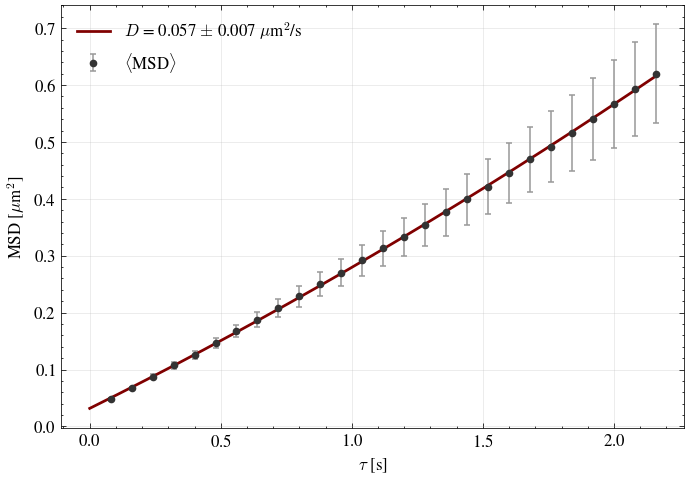

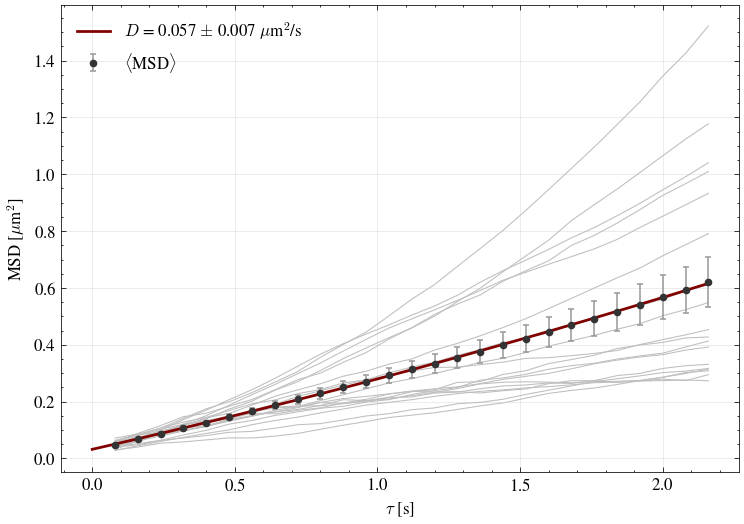

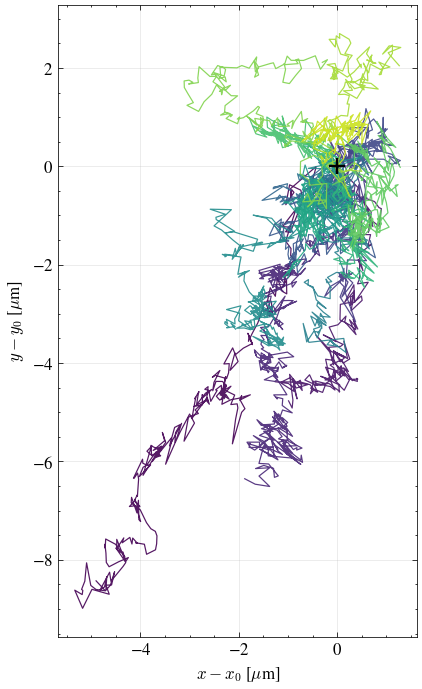

In [24]:
filas, curvas = [], {}
for pid in resumen.index:
    gi, xu, yu, hue = trayectoria_um(pid)
    n_lags = int(FRACCION_MSD*len(xu))
    if n_lags < 5:
        continue
    lg, mv, _ = msd(xu, yu, n_lags)
    s_, D_, dD_, v_, _, _, _ = ajustar(lg*DT, mv)
    if D_ <= 0:
        continue
    neto = np.hypot(xu[-1] - xu[0], yu[-1] - yu[0])
    filas.append({'id': pid, 'N': len(gi), 'huecos': hue,
                  'masa': resumen.loc[pid, 'masa'], 'sigma_px': s_/ESCALA_UM_PX,
                  'D': D_, 'dD': dD_, 'v': v_, 'eta': eta_de_D(D_),
                  'razon': neto/np.sqrt(4*D_*len(gi)*DT)})
    curvas[pid] = (lg, mv)

conj = pd.DataFrame(filas)
conj['acepta'] = ((conj['huecos'] <= MAX_HUECOS) &
                  (conj['sigma_px'] <= MAX_SIGMA_PX) &
                  (conj['razon'].between(MIN_RAZON, MAX_RAZON)))
acc = conj[conj['acepta']]
print(conj.round(4).to_string(index=False))
print(f"\naceptadas {len(acc)}/{len(conj)}")
for nombre, m in [('huecos', conj['huecos'] > MAX_HUECOS),
                  ('sigma', conj['sigma_px'] > MAX_SIGMA_PX),
                  ('razon', ~conj['razon'].between(MIN_RAZON, MAX_RAZON))]:
    if m.sum():
        print(f"   por {nombre}: {list(conj.loc[m, 'id'])}")

if len(acc) < 2:
    raise ValueError("Menos de dos trayectorias aceptadas.")

# MSD promedio. El conjunto de partículas debe ser el mismo en todos los
# retardos: si los retardos largos se promedian sobre las pocas trayectorias que
# llegan, que son las que más deriva acumulan, la curvatura del promedio queda
# inflada.

sel = [curvas[i] for i in acc['id']]
n_max = max(len(l) for l, _ in sel)
M = np.full((len(sel), n_max), np.nan)
for i, (l, m) in enumerate(sel):
    M[i, :len(m)] = m
cuenta = np.sum(~np.isnan(M), axis=0)
usar = cuenta >= max(2, min(MIN_PARTICULAS_LAG, len(sel)))
if usar.sum() < 8:                        # pocas trayectorias largas
    usar = cuenta >= 2
tau_e = np.arange(1, n_max + 1)[usar]*DT
msd_e = np.nanmean(M[:, usar], axis=0)
err_e = np.nanstd(M[:, usar], axis=0, ddof=1)/np.sqrt(cuenta[usar])

sg_e, D_e, dD_fit, v_e, dv_e, _, _ = ajustar(tau_e, msd_e)
eta_e = eta_de_D(D_e)

# La incerteza de D la domina la dispersión entre partículas, no el ajuste. La
# calibración entra al cuadrado.
rel_disp = acc['D'].std(ddof=1)/acc['D'].mean()/np.sqrt(len(acc))
rel_cal = 2*ESCALA_UM_PX_ERR/ESCALA_UM_PX
rel_D = np.hypot(rel_disp, rel_cal)
rel_eta = np.hypot(rel_D, RADIO_UM_ERR/RADIO_UM)

print(f"\nparticulas {len(acc)}   retardos hasta {tau_e[-1]:.1f} s")
print(f"sigma   {sg_e/ESCALA_UM_PX:.2f} px")
print(f"D       {D_e:.4f} +- {D_e*rel_D:.4f} um^2/s   ({100*rel_D:.0f} %)")
print(f"v       {v_e:.4f} +- {dv_e:.4f} um/s")
print(f"eta     {eta_e:.2f} +- {eta_e*rel_eta:.2f} mPa s   ({100*rel_eta:.0f} %)")
print(f"   dispersión {100*rel_disp:.1f} %, calibración {100*rel_cal:.1f} %, "
      f"radio {100*RADIO_UM_ERR/RADIO_UM:.1f} %")
print(f"en tau = {tau_e[-1]:.1f} s: difusión {4*D_e*tau_e[-1]:.3f}, "
      f"deriva {(v_e*tau_e[-1])**2:.3f} um^2")
if eta_e < ETA_REF:
    print(f"eta < {ETA_REF} mPa s: revisar la identificación de las partículas")

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.errorbar(tau_e, msd_e, yerr=err_e, fmt='o', ms=4, color='0.2',
            ecolor='0.6', capsize=2,
            label=f'$\\langle$MSD$\\rangle$')
tt = np.linspace(0, tau_e[-1], 300)
ax.plot(tt, 4*sg_e**2 + 4*D_e*tt + (v_e*tt)**2, '-', color='maroon', lw=1.8,
        label=f"$D$ = {D_e:.3f} $\\pm$ {D_e*rel_D:.3f} $\\mu$m$^2$/s")
ax.set_xlabel(r'$\tau$ [s]')
ax.set_ylabel(r'MSD [$\mu$m$^2$]')
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
guardar('conjunto')
plt.show()

pd.DataFrame({'frame': p.index, 't_s': t_s, 'x_um': x_um, 'y_um': y_um}) \
  .to_csv(os.path.join(SALIDA, 'trayectoria.csv'), index=False)
pd.DataFrame({'tau_s': tau_e, 'msd_um2': msd_e, 'err_um2': err_e}) \
  .to_csv(os.path.join(SALIDA, 'msd_conjunto.csv'), index=False)
conj.to_csv(os.path.join(SALIDA, 'conjunto.csv'), index=False)

fig, ax = plt.subplots(figsize=(7, 5))
for pid in acc['id']:
    lg, mv = curvas[pid]
    m = lg*DT <= tau_e[-1]
    ax.plot(lg[m]*DT, mv[m], '-', lw=0.7, color='0.75')
ax.errorbar(tau_e, msd_e, yerr=err_e, fmt='o', ms=4, color='0.2',
            ecolor='0.6', capsize=2, label=r'$\langle$MSD$\rangle$')
tt = np.linspace(0, tau_e[-1], 300)
ax.plot(tt, 4*sg_e**2 + 4*D_e*tt + (v_e*tt)**2, '-', lw=1.8, color='maroon',
        label=f'$D$ = {D_e:.3f} $\\pm$ {D_e*rel_D:.3f} $\\mu$m$^2$/s')
ax.set_xlabel(r'$\tau$ [s]')
ax.set_ylabel(r'MSD [$\mu$m$^2$]')
ax.legend(loc='upper left', frameon=False)
plt.tight_layout()
guardar('msd_18_gris')
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
cols = plt.cm.viridis(np.linspace(0, 0.92, len(acc)))
for c, (_, r) in zip(cols, acc.iterrows()):
    _, xu, yu, _ = trayectoria_um(r['id'])
    ax.plot(xu - xu[0], yu - yu[0], '-', lw=0.8, color=c, alpha=0.9)
ax.plot(0, 0, '+', color='k', ms=11, mew=1.6, zorder=5)
ax.set_xlabel(r'$x - x_0$ [$\mu$m]')
ax.set_ylabel(r'$y - y_0$ [$\mu$m]')
ax.set_aspect('equal')
plt.tight_layout()
guardar('trayectorias_18')
plt.show()

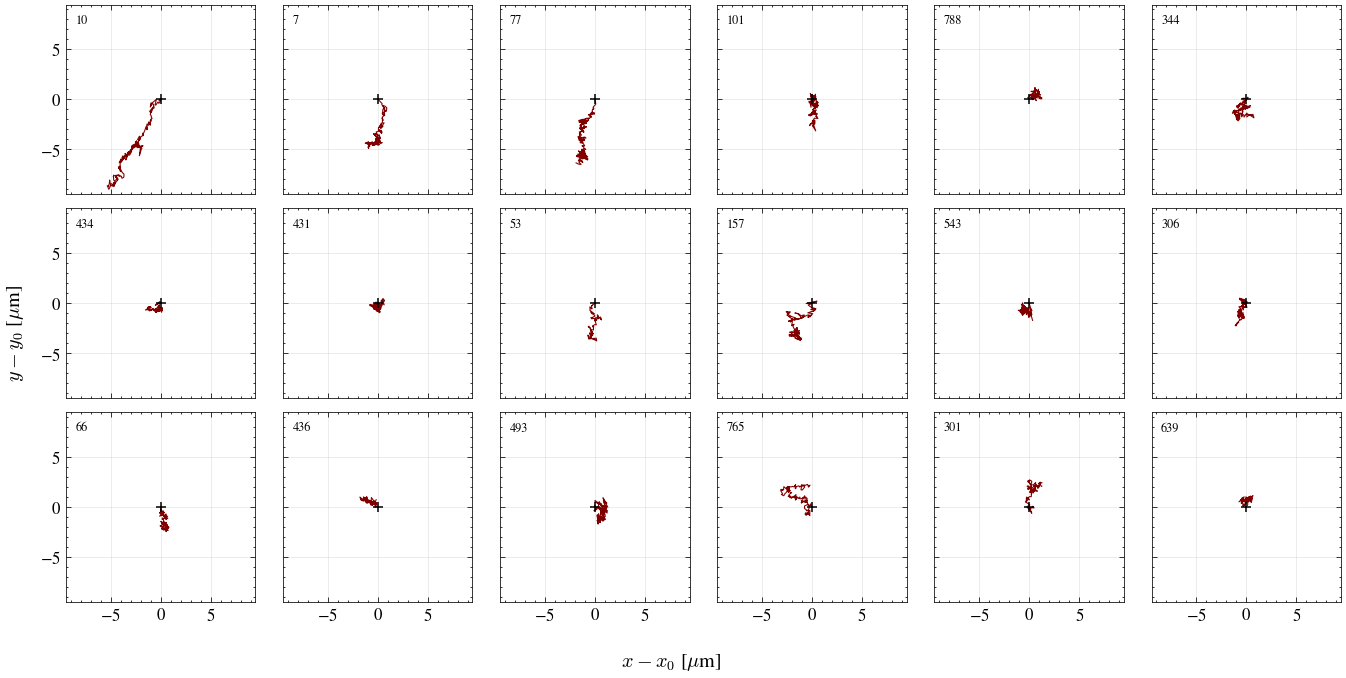

In [25]:
ncol = 6
tr = {}
for pid in acc['id']:
    _, xu, yu, _ = trayectoria_um(pid)
    tr[pid] = (xu - xu[0], yu - yu[0])
nfil = int(np.ceil(len(tr)/ncol))
lim = 1.05*max(max(np.abs(dx).max(), np.abs(dy).max()) for dx, dy in tr.values())

fig, axes = plt.subplots(nfil, ncol, figsize=(2.1*ncol, 2.1*nfil),
                         sharex=True, sharey=True)
for a, (pid, (dx, dy)) in zip(axes.ravel(), tr.items()):
    a.plot(dx, dy, '-', lw=0.7, color='maroon')
    a.plot(0, 0, '+', color='k', ms=6, mew=1.0)
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
    a.set_aspect('equal')
    a.text(0.05, 0.95, f'{pid}', transform=a.transAxes, va='top', fontsize=8)
for a in axes.ravel()[len(tr):]:
    a.axis('off')
fig.supxlabel(r'$x - x_0$ [$\mu$m]')
fig.supylabel(r'$y - y_0$ [$\mu$m]')
plt.tight_layout()
guardar('trayectorias_panel')
plt.show()

## 11. Sensibilidad a los parámetros

Se vuelve a medir la misma partícula variando un parámetro por vez. La  
partícula se identifica por su posición y no por su id, que tp.link reasigna  
en cada corrida. Si D varía menos que su incerteza, el resultado es robusto;  
si varía más, el parámetro es un sistemático y entra al presupuesto de error.

In [26]:
X_REF, Y_REF = pc.sort_index().iloc[0][['x', 'y']]
K_REF = int(pc.index.min())


def medir(sr, mem):
    try:
        tr = tp.link(detecciones, search_range=sr, memory=mem)
    except Exception:
        return None                       # search_range irresoluble: ya es un dato
    tr = tp.filter_stubs(tr, MIN_LARGO).reset_index(drop=True)
    if len(tr) == 0:
        return None
    disp = np.sort(tr['frame'].unique())
    k = int(disp[np.argmin(np.abs(disp - K_REF))])
    cer = tr[tr['frame'] == k]
    d = np.hypot(cer['x'] - X_REF, cer['y'] - Y_REF)
    if d.min() > DIAMETRO:
        return None
    gi, xu, yu, hue = trayectoria_um(int(cer.loc[d.idxmin(), 'particle']),
                                     tabla=tr)
    lg, mv, _ = msd(xu, yu, int(FRACCION_MSD*len(xu)))
    s_, D_, dD_, v_, _, _, _ = ajustar(lg*DT, mv)
    return {'sr': sr, 'mem': mem, 'N': len(gi), 'huecos': round(hue, 3),
            'sigma_px': s_/ESCALA_UM_PX, 'D': D_, 'dD': dD_, 'v': v_,
            'eta': eta_de_D(D_)}


print("SEARCH_RANGE")
print(pd.DataFrame([r for r in (medir(s, MEMORIA) for s in (5, 8, 10, 15, 25))
                    if r]).round(4).to_string(index=False))
print("\nMEMORIA")
print(pd.DataFrame([r for r in (medir(SEARCH_RANGE, m) for m in (0, 1, 3, 5, 10))
                    if r]).round(4).to_string(index=False))




SEARCH_RANGE
 sr  mem   N  huecos  sigma_px      D     dD      v    eta
  8    3 178   0.006    1.2151 0.0489 0.0035 0.0421 2.7573
 10    3 192   0.010    0.0000 0.1036 0.0027 0.0000 1.3009
 15    3 671   0.003    0.0000 0.2153 0.0033 0.0000 0.6262
 25    3 671   0.003    0.0000 0.2153 0.0033 0.0000 0.6262

MEMORIA
 sr  mem   N  huecos  sigma_px      D     dD      v    eta
  8    0 175   0.000    1.2838 0.0412 0.0036 0.0847 3.2693
  8    1 178   0.006    1.2151 0.0489 0.0035 0.0421 2.7573
  8    3 178   0.006    1.2151 0.0489 0.0035 0.0421 2.7573
  8    5 178   0.006    1.2151 0.0489 0.0035 0.0421 2.7573
  8   10 178   0.006    1.2151 0.0489 0.0035 0.0421 2.7573
